# SEEDS 01b — Large-tract landowner candidates from county parcel records
Step 1b of the stakeholder workflow. Pulls public parcel/assessment data per AOI county, aggregates holdings by owner,
classifies owner type, and writes **landowner candidates in the same schema as the stakeholder pool** plus parcel geometries.

**Workflow:** run this → LTNAL/ACI review `landowner_candidates.csv` and set `approved_for_invite=True` (and add contact info) → run `02` scoring notebook (it only ingests approved rows).

Sources (public):
* **TN (9 counties):** TN Comptroller Division of Property Assessments, Geographic Services — free county parcel shapefile downloads incl. `Assessment_Data_##.dbf` (owner, acreage, land use). All 9 AOI counties are in the state-maintained set. Download each county zip into `RAW_DIR/TN/`.
* **AL (Madison, Marshall, Jackson):** pulled automatically from public ArcGIS REST parcel services (Madison via City of Madison GIS, Jackson via KCS web3; Marshall candidates). Any file in `RAW_DIR/AL/` overrides.
* Any county: a Regrid (or other) export with owner + acreage fields works via the `file` reader.

Use for stakeholder outreach planning only; owner/mailing fields come from public tax rolls. Vet before contact.

In [ ]:
# ---------------- PARAMETERS ----------------
SYNTHETIC = False
OUT_DIR  = '/content/drive/MyDrive/SEEDS/stakeholder_mapping'
RAW_DIR  = f'{OUT_DIR}/parcels/raw'           # RAW_DIR/TN/<county>*.zip ; RAW_DIR/AL/<county>*.(zip|gpkg|geojson|csv)
MIN_PARCEL_ACRES  = 10                         # drop tiny parcels before aggregation
MIN_HOLDING_ACRES = 50                         # aggregated holding threshold ("large tract")
TOP_N_PER_COUNTY  = 50                         # private candidates kept per county (by acreage)
TOP_N_CORP_PER_COUNTY = 10                     # extra slots for timber/corporate holders
AOI = {'01089':'Madison AL','01095':'Marshall AL','01071':'Jackson AL','47051':'Franklin TN','47031':'Coffee TN','47061':'Grundy TN',
       '47115':'Marion TN','47153':'Sequatchie TN','47007':'Bledsoe TN','47177':'Warren TN','47041':'DeKalb TN','47175':'Van Buren TN'}
# per-county source. type: 'file' (glob under RAW_DIR) | 'arcgis' (layer URL ending /MapServer/<id> or /FeatureServer/<id>)
SOURCES = {cf: dict(type='file', glob=f"{'TN' if cf.startswith('47') else 'AL'}/*{nm.split()[0].replace(' ', '')}*") for cf, nm in AOI.items()}
# AL: public ArcGIS REST parcel services (auto-resolved parcel layer); falls back to RAW_DIR/AL files if a service fails
SOURCES['01089'].update(type='arcgis', county='Madison', services=[      # Madison Co. parcels via City of Madison GIS
    'https://maps.madisonal.gov/server/rest/services/Development_Dashboard_Base_MIL1/MapServer',
    'https://madmaps1.madisonal.gov/server/rest/services/Development_Dashboard_Base_MIL1/MapServer'])
SOURCES['01071'].update(type='arcgis', county='Jackson', url='https://web3.kcsgis.com/kcsgis/rest/services/Jackson/Public_ISV_Jackson/MapServer/1',
    services=['https://web3.kcsgis.com/kcsgis/rest/services/Jackson/Public_ISV_Jackson/MapServer'])
SOURCES['01095'].update(type='arcgis', county='Marshall', services=[     # candidates (KCS host migration) - unverified
    'https://web3.kcsgis.com/kcsgis/rest/services/Marshall/Public_ISV_Marshall/MapServer',
    'https://web4.kcsgis.com/kcsgis/rest/services/Marshall/Public_ISV_Marshall/MapServer',
    'https://web3.kcsgis.com/kcsgis/rest/services/Marshall/Public_ISV/MapServer'])
UPLOAD_MISSING_TN = True   # Colab: prompt to upload any missing TN county zips straight into Drive
FIELD_OVERRIDES = {}   # e.g. {'47051': dict(owner='OWNER', acres='CALC_ACRE', mail='MAILADDR')}
CRS = 'EPSG:5070'

In [ ]:
import os, sys, re, glob, json, math, zipfile, tempfile, warnings, urllib.request, urllib.parse
warnings.filterwarnings('ignore')
IN_COLAB = 'google.colab' in sys.modules
if IN_COLAB:
    import subprocess; subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'pyogrio', 'requests'])
    from google.colab import drive; drive.mount('/content/drive')
else:
    OUT_DIR = os.path.abspath(OUT_DIR.replace('/content/drive/MyDrive', './drive')); RAW_DIR = f'{OUT_DIR}/parcels/raw'
import numpy as np, pandas as pd, geopandas as gpd, matplotlib.pyplot as plt
from shapely.geometry import box
P_OUT = f'{OUT_DIR}/parcels'; os.makedirs(P_OUT, exist_ok=True)
for st in ('TN', 'AL'): os.makedirs(f'{RAW_DIR}/{st}', exist_ok=True)
print('raw dir:', RAW_DIR)

Mounted at /content/drive
raw dir: /content/drive/MyDrive/SEEDS/stakeholder_mapping/parcels/raw


## Stage TN county zips (Colab upload -> Drive)

In [ ]:
TN_NEED = {'47051': 'franklin', '47031': 'coffee', '47061': 'grundy', '47115': 'marion', '47153': 'sequatchie',
           '47007': 'bledsoe', '47177': 'warren', '47041': 'dekalb', '47175': 'vanburen'}
def _have_tn():
    fs = [f.lower().replace(' ', '') for f in os.listdir(f'{RAW_DIR}/TN')]
    return {k: v for k, v in TN_NEED.items() if any(v in f for f in fs)}
missing = [v for k, v in TN_NEED.items() if k not in _have_tn()]
print('TN zips present:', sorted(_have_tn().values())); print('TN zips missing:', missing)
if missing and IN_COLAB and UPLOAD_MISSING_TN:
    from google.colab import files
    print('Select the missing county zips (TN Comptroller downloads) ->'); up = files.upload()
    for name, data in up.items():
        open(os.path.join(RAW_DIR, 'TN', name.replace(' ', '')), 'wb').write(data)
    print('saved to Drive:', list(up))

TN zips present: ['bledsoe', 'coffee', 'dekalb', 'franklin', 'grundy', 'marion', 'sequatchie', 'vanburen', 'warren']
TN zips missing: []


## Source readers (ArcGIS REST with pagination · local files incl. TN Comptroller zips) + field auto-detect

In [ ]:
def _get(url, params=None):
    import requests
    r = requests.get(url, params=params, timeout=120); r.raise_for_status(); return r.json()

def discover(service_url):
    'Print layers + fields of an ArcGIS MapServer/FeatureServer to find the parcel layer and owner/acre fields.'
    j = _get(service_url.rstrip('/') + '/layers', {'f': 'json'})
    for L in j.get('layers', []):
        flds = [f['name'] for f in (L.get('fields') or [])]
        print(f"[{L['id']}] {L['name']} ({L.get('geometryType')}) maxRec={L.get('maxRecordCount')}\n    {flds[:40]}")

def resolve_parcel_layer(services, county=''):
    for svc in services:
        try:
            j = _get(svc.rstrip('/') + '/layers', {'f': 'json'})
            L = [l for l in j.get('layers', []) if l.get('geometryType') == 'esriGeometryPolygon' and re.search('parcel', l['name'], re.I)]
            L = [l for l in L if county.lower() in l['name'].lower()] or L
            if L: return f"{svc.rstrip('/')}/{L[0]['id']}"
        except Exception as e:
            print('   service failed:', svc, '-', str(e)[:80])
    return None

def arcgis_layer(url, where='1=1', page=None):
    meta = _get(url, {'f': 'json'}); page = page or meta.get('maxRecordCount', 1000) or 1000
    if meta.get('advancedQueryCapabilities', {}).get('supportsPagination', True):
        out, off = [], 0
        while True:
            j = _get(url.rstrip('/') + '/query', {'where': where, 'outFields': '*', 'outSR': 4326, 'f': 'geojson',
                                                  'resultOffset': off, 'resultRecordCount': page, 'returnGeometry': 'true'})
            feats = j.get('features', []); out += feats; off += len(feats)
            print(f'  fetched {off:,}', end='\r')
            if len(feats) < page and not j.get('exceededTransferLimit'): break
            if not feats: break
    else:
        ids = _get(url.rstrip('/') + '/query', {'where': where, 'returnIdsOnly': 'true', 'f': 'json'})['objectIds']; out = []
        for i in range(0, len(ids), page):
            j = _get(url.rstrip('/') + '/query', {'objectIds': ','.join(map(str, ids[i:i + page])), 'outFields': '*', 'outSR': 4326, 'f': 'geojson'})
            out += j.get('features', [])
    return gpd.GeoDataFrame.from_features(out, crs=4326)

def read_files(pattern):
    st, pat = os.path.split(pattern)
    key = pat.strip('*').lower()
    paths = sorted(p for p in glob.glob(os.path.join(RAW_DIR, st, '**', '*'), recursive=True)
                   if os.path.isfile(p) and key in os.path.basename(p).lower().replace(' ', '')
                   and p.lower().endswith(('.zip', '.shp', '.gpkg', '.geojson', '.json', '.csv', '.gdb.zip')))
    if not paths: return None
    frames = []
    for p in paths:
        if p.lower().endswith('.zip'):
            d = tempfile.mkdtemp(); zipfile.ZipFile(p).extractall(d)
            shp = [f for f in glob.glob(f'{d}/**/*.shp', recursive=True)]
            if not shp: continue
            g = max((gpd.read_file(f) for f in shp), key=len)                       # parcel polygons
            dbf = [f for f in glob.glob(f'{d}/**/*.dbf', recursive=True) if re.search('assess', os.path.basename(f), re.I)]
            if dbf:                                                                # TN Comptroller: join Assessment_Data table
                t = gpd.read_file(dbf[0]); t = pd.DataFrame(t.drop(columns='geometry', errors='ignore'))
                key = next((k for k in ['GISLINK', 'PARCELID', 'PARCEL_ID', 'PID', 'PIN'] if k in g.columns and k in t.columns), None)
                if key: g = g.merge(t, on=key, how='left', suffixes=('', '_a'))
            frames.append(g)
        elif p.lower().endswith('.csv'):
            t = pd.read_csv(p); gcol = next((c for c in t.columns if c.lower() in ('geometry', 'wkt', 'geom')), None)
            frames.append(gpd.GeoDataFrame(t, geometry=gpd.GeoSeries.from_wkt(t[gcol]), crs=4326) if gcol else gpd.GeoDataFrame(t))
        else:
            frames.append(gpd.read_file(p))
    return pd.concat(frames, ignore_index=True) if frames else None

def pick(cols, pats, avoid=()):
    for pat in pats:
        for c in cols:
            if re.fullmatch(pat, c, re.I) and not any(re.search(a, c, re.I) for a in avoid): return c
    for pat in pats:
        for c in cols:
            if re.search(pat, c, re.I) and not any(re.search(a, c, re.I) for a in avoid): return c
    return None

def detect_fields(df, cf):
    cols = list(df.columns); o = FIELD_OVERRIDES.get(cf, {})
    return dict(
        owner=o.get('owner') or pick(cols, [r'owner', r'owner1', r'ownername', r'own_?name', r'owner_name', r'ownnme', r'own1', r'own'], avoid=[r'addr', r'city', r'zip', r'state', r'date']),
        acres=o.get('acres') or pick(cols, [r'calc_?acre?s?', r'gis_?acres?', r'deed_?ac(res)?', r'acres?', r'll_gisacre', r'.*acre.*', r'.*ac$']),
        mail=o.get('mail') or pick(cols, [r'mail_?addr(ess)?1?', r'own_?addr(ess)?1?', r'mailadd', r'.*mail.*'], avoid=[r'city', r'zip', r'state']),
        mcity=o.get('mcity') or pick(cols, [r'mail_?city', r'own_?city', r'.*city.*']),
        mstate=o.get('mstate') or pick(cols, [r'mail_?state', r'own_?state', r'.*state$'], avoid=[r'statefp']),
        pid=o.get('pid') or pick(cols, [r'parcel_?id', r'gislink', r'ppin', r'pin', r'parcel.*', r'parno']),
        landuse=o.get('landuse') or pick(cols, [r'land_?use', r'luc', r'prop_?class', r'.*use.*']))

## Owner normalization + classification

In [ ]:
PUBLIC = r'\b(STATE OF|UNITED STATES|U ?S A\b|USA\b|TENNESSEE VALLEY|T ?V ?A\b|CITY OF|TOWN OF|COUNTY|BOARD OF|DEPT|DEPARTMENT|COMMISSION|AUTHORITY|UTILITY|UTILITIES|SCHOOL|HOUSING|ARMY|AIR FORCE|NASA|CORPS OF ENGINEERS|WILDLIFE RESOURCES|FOREVER WILD|STATE PARK)\b'
NGO    = r'\b(CONSERVANCY|LAND TRUST|CONSERVATION FUND|OPEN SPACE INSTITUTE|TENNGREEN|AUDUBON|CAVE CONSERVANCY|FOUNDATION)\b'
INST   = r'\b(UNIVERSITY|COLLEGE|CHURCH|ASSEMBLY|DIOCESE|MINISTR|BAPTIST|METHODIST|CAMP)\b'
TIMBER = r'\b(TIMBER|TIMBERLANDS?|FOREST(S|RY)?|WOODLANDS?|LUMBER|PAPER|RESOURCES|LAND CO|LAND COMPANY|HANCOCK|MOLPUS|RAYONIER|WEYERHAEUSER|CAMPBELL GLOBAL|FORESTLAND GROUP|TIMO)\b'
CORP   = r'\b(LLC|L L C|INC|CORP|CORPORATION|COMPANY|CO\b|LP\b|LLP|LTD|PARTNERS|PARTNERSHIP|HOLDINGS|PROPERTIES|ENTERPRISES|FARMS? LLC|INVESTMENTS?)\b'
TRUST  = r'\b(TRUST|TRUSTEE|TR\b|ESTATE|ESTATE OF|REVOCABLE|LIVING TR)\b'
def norm_owner(s):
    s = re.sub(r'[^A-Z0-9& ]', ' ', str(s).upper())
    s = re.sub(r'\b(ETUX|ET UX|ETAL|ET AL|ETVIR|ET VIR|JR|SR|II|III|LIFE ESTATE|LE|C/O)\b', ' ', s)
    return re.sub(r'\s+', ' ', s).strip()
def owner_type(n):
    if re.search(PUBLIC, n): return 'public'
    if re.search(NGO, n): return 'ngo'
    if re.search(INST, n): return 'institutional'
    if re.search(TIMBER, n): return 'timber/forest company'
    if re.search(CORP, n): return 'corporate/LLC'
    if re.search(TRUST, n): return 'trust/estate'
    return 'individual/family'

## Pull + aggregate per county

In [ ]:
def synthetic_parcels(cf, seed=0):
    rng = np.random.default_rng(int(cf)); cen = {'01089':(34.76,-86.55),'01095':(34.37,-86.30),'01071':(34.78,-85.99),'47051':(35.15,-86.10),
      '47031':(35.49,-86.08),'47061':(35.39,-85.72),'47115':(35.13,-85.62),'47153':(35.37,-85.41),'47007':(35.60,-85.21),
      '47177':(35.68,-85.78),'47041':(35.98,-85.83),'47175':(35.70,-85.46)}[cf]
    c = gpd.GeoSeries.from_xy([cen[1]], [cen[0]], crs=4326).to_crs(CRS).iloc[0]
    names = ['SMITH JOHN ETUX', 'JONES FAMILY TRUST', 'CUMBERLAND TIMBER LLC', 'STATE OF TENNESSEE', 'THE NATURE CONSERVANCY',
             'BROWN MARY', 'PLATEAU HOLDINGS LLC', 'TENNESSEE VALLEY AUTHORITY', 'WILLIAMS FARMS INC', 'DAVIS ESTATE', 'HANCOCK FOREST PARTNERS']
    rows = []
    for i in range(400):
        x, y = c.x + rng.uniform(-14e3, 14e3), c.y + rng.uniform(-14e3, 14e3); s = rng.lognormal(5, 1.1)
        rows.append(dict(OWNER=names[i % len(names)] if i < 120 else f'OWNER {i}', CALC_ACRE=(s * s) / 4046.86, MAILADDR=f'{i} MAIN ST',
                         MAILCITY='TOWN', MAILSTATE='TN', GISLINK=f'{cf}-{i}', geometry=box(x, y, x + s, y + s)))
    return gpd.GeoDataFrame(rows, crs=CRS).to_crs(4326)

hold_all, parcels_all, log = [], [], []
for cf, nm in AOI.items():
    src = SOURCES[cf]
    try:
        if SYNTHETIC: g = synthetic_parcels(cf)
        else:
            g = read_files(src['glob'])                                   # local/Drive files win if present
            if (g is None or len(g) == 0) and src['type'] == 'arcgis':
                for url in [src.get('url')] + [None]:
                    url = url or resolve_parcel_layer(src.get('services', []), src.get('county', ''))
                    if not url: break
                    try:
                        print(f'{nm} -> ArcGIS {url}'); g = arcgis_layer(url, src.get('where', '1=1')); print(f'   {len(g):,} features'); break
                    except Exception as e:
                        print('   failed:', str(e)[:100]); g = None; src['url'] = None
        if g is None or len(g) == 0:
            log.append((nm, 'NO DATA - add files to ' + os.path.join(RAW_DIR, src.get('glob', '')) + ' or set arcgis url')); continue
        if g.crs is None: g = g.set_crs(4326)
        f = detect_fields(g, cf)
        if not f['owner']: log.append((nm, f'owner field not found: {list(g.columns)[:30]}')); continue
        g = g.to_crs(CRS)
        g['acres'] = pd.to_numeric(g[f['acres']], errors='coerce') if f['acres'] else np.nan
        g['acres'] = g['acres'].where(g['acres'] > 0, g.area / 4046.86)
        g = g[g.acres >= MIN_PARCEL_ACRES].copy()
        g['owner_raw'] = g[f['owner']].astype(str); g['owner_norm'] = g.owner_raw.map(norm_owner)
        g['owner_type'] = g.owner_norm.map(owner_type); g['cfips'] = cf
        g['mail'] = ' '.join([]) if not f['mail'] else g[f['mail']].astype(str)
        g['mail_city_state'] = (g[f['mcity']].astype(str) if f['mcity'] else '') + (' ' + g[f['mstate']].astype(str) if f['mstate'] else '')
        g['parcel_id'] = g[f['pid']].astype(str) if f['pid'] else g.index.astype(str)
        g['land_use'] = g[f['landuse']].astype(str) if f['landuse'] else ''
        parcels_all.append(g[['cfips', 'parcel_id', 'owner_raw', 'owner_norm', 'owner_type', 'acres', 'land_use', 'mail', 'mail_city_state', 'geometry']])
        h = g.dissolve('owner_norm', aggfunc={'owner_raw': 'first', 'owner_type': 'first', 'acres': 'sum', 'parcel_id': 'count',
                                              'mail': 'first', 'mail_city_state': 'first', 'land_use': lambda s: ';'.join(sorted(set(s)))[:120]}).reset_index()
        h = h.rename(columns={'parcel_id': 'n_parcels'}); h['cfips'] = cf; h['county'] = nm
        hold_all.append(h); log.append((nm, f'{len(g):,} parcels >= {MIN_PARCEL_ACRES} ac; fields={f}'))
    except Exception as e:
        log.append((nm, f'ERROR {e}'))
for l in log: print(*l, sep=' : ')
H = gpd.GeoDataFrame(pd.concat(hold_all, ignore_index=True), crs=CRS) if hold_all else None
if H is None or H.empty:
    msg = f'''
NO PARCEL DATA LOADED - nothing to aggregate. Fill RAW_DIR then re-run this cell:
  {RAW_DIR}/TN/  <- one zip per county from TN Comptroller (manual request form, one county at a time):
     https://comptroller.tn.gov/office-functions/pa/gisredistricting/redistricting-and-land-use-maps/parcel-data.html
     file name must contain the county name, e.g. Franklin_parcels.zip, VanBuren.zip
  {RAW_DIR}/AL/  <- Madison/Marshall/Jackson export (Regrid / Revenue Commissioner), OR set
     SOURCES['01071'] = dict(type='arcgis', url='<.../MapServer/<parcel layer id>>')  (use discover(service_url))
Counties with data can run alone - the rest are skipped.'''
    print(msg); raise SystemExit('stop: add parcel data')
print(f'{len(H):,} owner holdings across', H.county.nunique(), 'counties')

Madison AL -> ArcGIS https://maps.madisonal.gov/server/rest/services/Development_Dashboard_Base_MIL1/MapServer/1
   failed: Expecting value: line 3 column 1 (char 4)
Madison AL -> ArcGIS https://maps.madisonal.gov/server/rest/services/Development_Dashboard_Base_MIL1/MapServer/1
   failed: Expecting value: line 3 column 1 (char 4)
Jackson AL -> ArcGIS https://web3.kcsgis.com/kcsgis/rest/services/Jackson/Public_ISV_Jackson/MapServer/1
   44,981 features
Madison AL : NO DATA - add files to /content/drive/MyDrive/SEEDS/stakeholder_mapping/parcels/raw/AL/*Madison* or set arcgis url
Marshall AL : NO DATA - add files to /content/drive/MyDrive/SEEDS/stakeholder_mapping/parcels/raw/AL/*Marshall* or set arcgis url
Jackson AL : 11,323 parcels >= 10 ac; fields={'owner': 'Owner', 'acres': 'CalcAcres', 'mail': 'MailAdd1', 'mcity': 'MailCity', 'mstate': 'MailState', 'pid': 'PARCELID', 'landuse': 'created_user'}
Franklin TN : owner field not found: ['FeatureID', 'ZOrder', 'Annotation', 'SymbolID', 'St

## Large-tract candidates (private) → pool schema

200 landowner candidates -> /content/drive/MyDrive/SEEDS/stakeholder_mapping/parcels


n     acres
county       owner_type                         
Bledsoe TN   corporate/LLC           8  118938.0
             individual/family      29  330004.0
             timber/forest company   2   41235.0
             trust/estate           11  126379.0
Grundy TN    corporate/LLC          15   30289.0
             individual/family      30   36388.0
             timber/forest company   4   19200.0
             trust/estate            1    1119.0
Jackson AL   corporate/LLC          26   67136.0
             individual/family      18   28048.0
             timber/forest company   2   19494.0
             trust/estate            4    4302.0
Van Buren TN corporate/LLC          15   64263.0
             individual/family      34   52661.0
             timber/forest company   1    1230.0

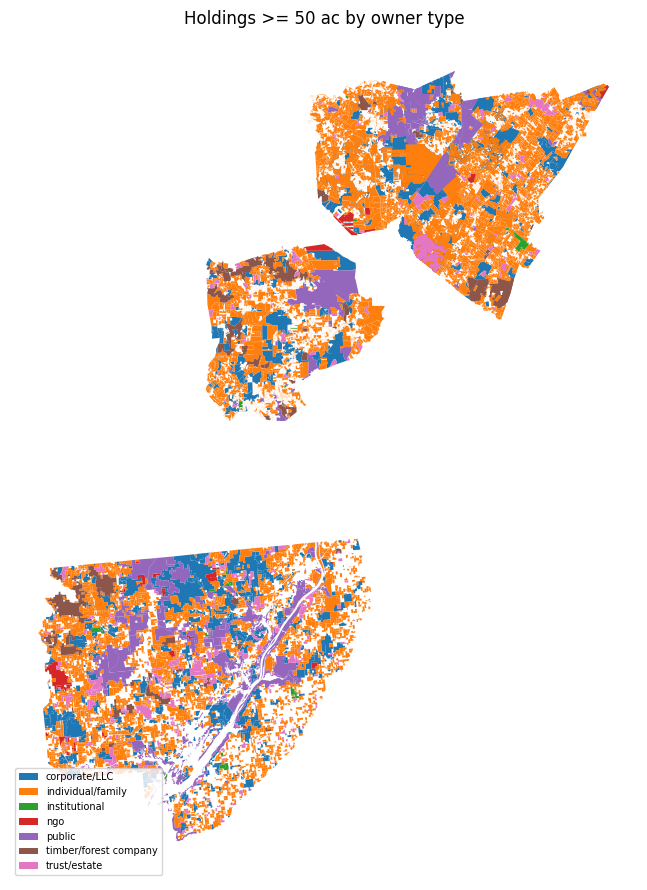

In [ ]:
H['large'] = H.acres >= MIN_HOLDING_ACRES
private = H[H.large & H.owner_type.isin(['individual/family', 'trust/estate', 'corporate/LLC', 'timber/forest company', 'institutional'])].copy()
private['rank_in_county'] = private.groupby('cfips').acres.rank(ascending=False, method='first')
corp = private.owner_type.isin(['timber/forest company', 'corporate/LLC'])
keep = (private.rank_in_county <= TOP_N_PER_COUNTY) | (corp & (private.groupby('cfips').acres.rank(ascending=False) <= TOP_N_CORP_PER_COUNTY))
cand = private[keep].sort_values(['cfips', 'acres'], ascending=[True, False]).reset_index(drop=True)
cand['stakeholder_id'] = [f'LO-{c}-{i:03d}' for c, i in zip(cand.cfips, cand.groupby('cfips').cumcount() + 1)]

RC = {'individual/family': ('private_landowner', 'Private Landowner', 'Landowner'),
      'trust/estate': ('private_landowner', 'Private Landowner', 'Trustee / family representative'),
      'corporate/LLC': ('industry_company', 'Industry/Private Sector', 'Land manager / managing member'),
      'timber/forest company': ('industry_company', 'Industry/Private Sector', 'Regional forester / land manager'),
      'institutional': ('institutional_landowner', 'Private Landowner', 'Property / land manager')}
DIMS = {'private_landowner': (1, .1, 1.0, 1.0, .5, 0, .9, .8), 'industry_company': (2, .3, .9, .7, .7, .1, .7, .6),
        'institutional_landowner': (2, .3, .9, .6, .5, .1, .6, .6)}
rows = []
for r in cand.itertuples():
    rc, sec, role = RC[r.owner_type]; d = DIMS[rc]
    rows.append(dict(stakeholder_id=r.stakeholder_id, org=r.owner_raw, poc_name=r.owner_raw if rc == 'private_landowner' else 'TBD - land manager',
                     poc_role=role, poc_email='', email_basis='none', verify_flag='Y', source_url='county parcel / assessment records', as_of='',
                     sector=sec, sub_sector=f'{r.owner_type} ({r.acres:,.0f} ac, {r.n_parcels} parcels)', role_class=rc, event_region='',
                     event_name='auto', priority=2, geo_type='override', geo_ref=r.stakeholder_id, counties_fips=r.cfips, counties=r.county,
                     lat='', lon='', approx_acres=round(r.acres), authority=d[0], constituency=d[1], d_control=d[2], d_approval=d[3],
                     d_fiscal=d[4], d_authority=d[5], d_speed=d[6], d_freedom=d[7], geom_status='parcel (county records)',
                     approved_for_invite=False, src_tag='parcel_pull',
                     notes=f'mail on file: {"Y" if str(r.mail).strip() not in ("", "nan") else "N"} | land use: {r.land_use} | VET via LTNAL/ACI before contact'))
LC = pd.DataFrame(rows)
LC.to_csv(f'{P_OUT}/landowner_candidates.csv', index=False)
cand[['stakeholder_id', 'geometry']].to_crs(4326).to_file(f'{P_OUT}/landowner_parcels.geojson', driver='GeoJSON')
# review sheet (with mailing fields) + full holdings incl. public/NGO for cross-check against the institutional pool
cand.drop(columns='geometry').round(1).to_csv(f'{P_OUT}/landowner_review_sheet.csv', index=False)
H.drop(columns='geometry').round(1).sort_values(['cfips', 'acres'], ascending=[True, False]).to_csv(f'{P_OUT}/holdings_all_owner_types.csv', index=False)
print(len(LC), 'landowner candidates ->', P_OUT)
display(cand.groupby(['county', 'owner_type']).agg(n=('acres', 'size'), acres=('acres', 'sum')).round(0))

fig, ax = plt.subplots(figsize=(10, 9))
H[H.large].plot('owner_type', ax=ax, legend=True, categorical=True, cmap='tab10', linewidth=0, legend_kwds={'fontsize': 7, 'loc': 'lower left'})
ax.set_title(f'Holdings >= {MIN_HOLDING_ACRES} ac by owner type'); ax.set_axis_off(); fig.tight_layout()
fig.savefig(f'{P_OUT}/holdings_by_owner_type.png', dpi=180); plt.show()

## Next
1. Open `landowner_review_sheet.csv` with LTNAL/ACI → mark `approved_for_invite=True` in `landowner_candidates.csv`, add phone/email where known.
2. Run `02_SEEDS_Stakeholder_Influence_Ability.ipynb` — it merges approved landowners and uses `landowner_parcels.geojson` as their footprints.